<a href="https://colab.research.google.com/github/AnushaRumi/AegisAI/blob/main/SM_CNN_traffic_sign_colab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Siamese-Mamba&CNN (SM&CNN) for Traffic Sign Recognition
Re-implementation of **"Improved road traffic sign recognition from feature reconstruction"** (Huang et al., *Scientific Reports* 15:42656, 2025) for **Google Colab**.

**What is implemented**
* Siamese network: shared encoder, pair head trained with `BCEWithLogitsLoss` (Eq. 16)
* Improved Mamba branch: patch-embed -> SS-Conv-SSM blocks (SS2D selective-scan branch + **DS Block** depth-separable conv branch, channel shuffle) -> patch merging (Figs. 2-3, Eqs. 1-3)
* Configurable CNN backbone: VGG-16 / ResNet-50 / MobileNetV2 / AlexNet (ImageNet-pretrained)
* **HN-FR** module: attention weighting + two fully-connected fusion layers (Fig. 4, Eqs. 8-14)
* SGD (momentum 0.9), cosine annealing (Eq. 20), AMP, freeze -> unfreeze training
* Datasets: **GTSRB** (auto-download), **TSRD** (manual download), **TT100K** (manual/auto download, sign crops are cut from the detection annotations)
* Ablation switches (no DS block / no HN-FR / no Mamba) to mirror Table 8

**How to run:** `Runtime -> Change runtime type -> GPU`, then `Runtime -> Run all`. Edit the `CFG` cell first (dataset, backbone, epochs).

**Inference of test images (classification):** each test image is compared with a class prototype (mean embedding of up to `support_per_class` training images of that class) using the learned pair head; the class with the highest similarity wins.

## 1. Setup

In [1]:
# %pip install -q kagglehub scikit-learn tqdm matplotlib pandas
import os
os.system("nvidia-smi -L")

0

## 2. Configuration

In [2]:
CFG = dict(
    # ---- what to run ----
    dataset="GTSRB",            # "GTSRB" | "TSRD" | "TT100K"
    backbone="vgg16",           # "vgg16" | "resnet50" | "mobilenet_v2" | "alexnet"
    # ---- ablation switches (paper Table 8) ----
    use_mamba=True,             # False -> CNN only ("without the improved Mamba")
    use_ds=True,                # False -> original 3x3 conv branch instead of DS block
    use_hnfr=True,              # False -> plain concat + FC fusion
    # ---- model ----
    img_size=64,                # must be a multiple of 16 and >= 64
    embed_dim=256,
    mamba_dims=(64, 128, 256),
    mamba_depths=(2, 2, 2),
    d_state=8,
    pretrained=True,            # ImageNet weights for the CNN backbone
    use_mamba_ssm_kernel=False, # True: use the CUDA kernel of `pip install mamba-ssm` if installed (much faster)
    # ---- training ----
    epochs=5,                  # paper: 300 (reduce/increase to fit your Colab time)
    freeze_epochs=3,            # CNN backbone frozen for the first N epochs, then unfrozen
    batch_size=128,             # pairs per batch (lower to 64 if you hit OOM)
    samples_per_epoch=15000,    # anchors per epoch (None = whole training set)
    lr=0.01,
    backbone_lr_factor=0.1,     # lr multiplier for the pretrained CNN once unfrozen
    momentum=0.9,
    weight_decay=5e-4,
    val_fraction=0.1,           # held out from TRAIN to pick the best epoch (test set is never used for selection)
    support_per_class=20,       # images per class used to build prototypes at inference
    num_workers=2,
    seed=42,
    # ---- paths ----
    work_dir="/content/work",
    use_drive=False,            # True -> mount Google Drive (to keep datasets/checkpoints between sessions)
    tsrd_root="/content/drive/MyDrive/TSRD",    # folder that holds the TSRD train + test images (see below)
    tt100k_root="/content/tt100k",              # folder that holds (or will hold) the TT100K "data" directory
    tt100k_download=False,      # True -> wget the ~18 GB TT100K archive into tt100k_root
    tt100k_min_instances=5,     # keep sign classes with >= this many TRAIN crops (paper uses 173 classes -> try 1)
)
os.makedirs(CFG["work_dir"], exist_ok=True)

if CFG["use_drive"]:
    from google.colab import drive
    drive.mount("/content/drive")

## 3. Imports and helpers

In [3]:
import os, sys, math, json, random, time, re, subprocess
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, RandomSampler
from torchvision.transforms import v2
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("device:", device, "| torch", torch.__version__)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def to_tensor_img(img, S):
    """PIL image -> uint8 tensor (3,S,S)."""
    img = img.convert("RGB").resize((S, S), Image.BILINEAR)
    return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).contiguous()


def load_many(fn, n, desc, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        return list(tqdm(ex.map(fn, range(n)), total=n, desc=desc))

device: cuda | torch 2.14.1+cu130


## 4. Datasets

| Dataset | How it is obtained |
|---|---|
| **GTSRB** | automatic (`torchvision.datasets.GTSRB`, Kaggle mirror as fallback) |
| **TSRD** | download *TSRD-Train* and *TSRD-Test* (+ annotation txt files) from the official page `nlpr.ia.ac.cn/pal/trafficdata/recognition.html` (or a Kaggle mirror), unzip them into `CFG["tsrd_root"]`. Labels are read from the annotation files, or from the `NNN_xxxx.png` file-name prefix. |
| **TT100K** | `tt100k_download=True` downloads `data.zip` from `cg.cs.tsinghua.edu.cn/traffic-sign/` (~18 GB), or unzip it yourself into `CFG["tt100k_root"]`. Sign crops are cut from `annotations.json` (train/test as defined by the authors). |

In [4]:
def load_gtsrb(cfg):
    S = cfg["img_size"]
    root = os.path.join(cfg["work_dir"], "gtsrb")
    try:
        from torchvision.datasets import GTSRB
        tr = GTSRB(root, split="train", download=True)
        te = GTSRB(root, split="test", download=True)

        def conv(ds, name):
            def g(i):
                img, lab = ds[i]
                return to_tensor_img(img, S), int(lab)
            res = load_many(g, len(ds), name)
            return torch.stack([r[0] for r in res]), torch.tensor([r[1] for r in res])
        Xtr, ytr = conv(tr, "GTSRB train")
        Xte, yte = conv(te, "GTSRB test")
    except Exception as e:  # fallback: Kaggle mirror
        print("torchvision GTSRB failed (", repr(e), ") -> trying Kaggle mirror via kagglehub")
        import kagglehub, pandas as pd
        path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")

        def conv_csv(csv, name):
            df = pd.read_csv(os.path.join(path, csv))
            def g(i):
                img = Image.open(os.path.join(path, df["Path"].iloc[i]))
                return to_tensor_img(img, S), int(df["ClassId"].iloc[i])
            res = load_many(g, len(df), name)
            return torch.stack([r[0] for r in res]), torch.tensor([r[1] for r in res])
        Xtr, ytr = conv_csv("Train.csv", "GTSRB train")
        Xte, yte = conv_csv("Test.csv", "GTSRB test")
    return dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, num_classes=int(ytr.max()) + 1)


IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".ppm")


def _has_images(d):
    for _, _, fs in os.walk(d):
        if any(f.lower().endswith(IMG_EXT) for f in fs):
            return True
    return False


def _find_split_dir(root, key):
    for dp, dns, _ in os.walk(root):
        for d in sorted(dns):
            full = os.path.join(dp, d)
            if key in d.lower() and _has_images(full):
                return full
    return None


def _read_annotations(root, key):
    """TSRD annotation lines: name;width;height;x1;y1;x2;y2;classId;"""
    m = {}
    for dp, _, fs in os.walk(root):
        for f in fs:
            if f.lower().endswith(".txt") and key in f.lower():
                with open(os.path.join(dp, f), errors="ignore") as fh:
                    for line in fh:
                        p = [t.strip() for t in line.strip().split(";") if t.strip() != ""]
                        if len(p) >= 8 and p[0].lower().endswith(IMG_EXT):
                            try:
                                m[p[0]] = str(int(p[7]))
                            except ValueError:
                                pass
    return m


def _label_for(path, ann):
    b = os.path.basename(path)
    if b in ann:
        return ann[b]
    mm = re.match(r"^(\d+)_", b)
    if mm:
        return str(int(mm.group(1)))
    return os.path.basename(os.path.dirname(path))


def load_tsrd(cfg):
    S, root = cfg["img_size"], cfg["tsrd_root"]
    assert os.path.isdir(root), f"TSRD folder not found: {root}. See the dataset table above."
    dtr, dte = _find_split_dir(root, "train"), _find_split_dir(root, "test")
    assert dtr and dte, f"Could not find train/test image folders inside {root}"
    print("TSRD train dir:", dtr, "\nTSRD test dir :", dte)
    ann_tr, ann_te = _read_annotations(root, "train"), _read_annotations(root, "test")

    def collect(d, ann):
        files = sorted(os.path.join(dp, f) for dp, _, fs in os.walk(d) for f in fs if f.lower().endswith(IMG_EXT))
        return files, [_label_for(f, ann) for f in files]
    ftr, ltr = collect(dtr, ann_tr)
    fte, lte = collect(dte, ann_te)
    classes = sorted(set(ltr))
    cmap = {c: i for i, c in enumerate(classes)}
    keep = [i for i, l in enumerate(lte) if l in cmap]
    fte, lte = [fte[i] for i in keep], [lte[i] for i in keep]

    def conv(files, labs, name):
        def g(i):
            return to_tensor_img(Image.open(files[i]), S)
        X = torch.stack(load_many(g, len(files), name))
        return X, torch.tensor([cmap[l] for l in labs])
    Xtr, ytr = conv(ftr, ltr, "TSRD train")
    Xte, yte = conv(fte, lte, "TSRD test")
    return dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, num_classes=len(classes), class_names=classes)


def load_tt100k(cfg):
    S, root = cfg["img_size"], cfg["tt100k_root"]

    def find_ann():
        for dp, _, fs in os.walk(root):
            if "annotations.json" in fs:
                return os.path.join(dp, "annotations.json")
        return None
    ann_path = find_ann() if os.path.isdir(root) else None
    if ann_path is None and cfg["tt100k_download"]:
        os.makedirs(root, exist_ok=True)
        url = "http://cg.cs.tsinghua.edu.cn/traffic-sign/data_model_code/data.zip"
        print("Downloading TT100K (~18 GB), this takes a while ...")
        os.system(f"wget -c -q --show-progress {url} -O {root}/data.zip && unzip -q -o {root}/data.zip -d {root}")
        ann_path = find_ann()
    assert ann_path, f"annotations.json not found under {root}. Download TT100K (see the dataset table)."
    data_dir = os.path.dirname(ann_path)
    ann = json.load(open(ann_path))
    per_img = []  # (relative path, split, [(cat, bbox), ...])
    for _, v in ann["imgs"].items():
        p = v["path"]
        split = "train" if p.startswith("train") else "test" if p.startswith("test") else None
        if split and v.get("objects"):
            per_img.append((p, split, [(o["category"], o["bbox"]) for o in v["objects"]]))
    print("annotated images (train+test):", len(per_img))

    def crops(i):
        p, split, objs = per_img[i]
        out = []
        try:
            img = Image.open(os.path.join(data_dir, p)).convert("RGB")
        except Exception:
            return out
        for cat, b in objs:
            w, h = b["xmax"] - b["xmin"], b["ymax"] - b["ymin"]
            if w < 8 or h < 8:
                continue
            m = 0.1
            box = (max(0, int(b["xmin"] - m * w)), max(0, int(b["ymin"] - m * h)),
                   min(img.width, int(b["xmax"] + m * w)), min(img.height, int(b["ymax"] + m * h)))
            out.append((to_tensor_img(img.crop(box), S), cat, split))
        return out
    res = [c for lst in load_many(crops, len(per_img), "TT100K crops") for c in lst]
    cnt = {}
    for _, cat, sp in res:
        if sp == "train":
            cnt[cat] = cnt.get(cat, 0) + 1
    classes = sorted(c for c, n in cnt.items() if n >= cfg["tt100k_min_instances"])
    cmap = {c: i for i, c in enumerate(classes)}
    tr = [(x, cmap[c]) for x, c, s in res if s == "train" and c in cmap]
    te = [(x, cmap[c]) for x, c, s in res if s == "test" and c in cmap]
    print(f"TT100K: {len(classes)} classes | train crops {len(tr)} | test crops {len(te)}")
    return dict(Xtr=torch.stack([a for a, _ in tr]), ytr=torch.tensor([b for _, b in tr]),
                Xte=torch.stack([a for a, _ in te]), yte=torch.tensor([b for _, b in te]),
                num_classes=len(classes), class_names=classes)


def load_dataset(cfg):
    name, S = cfg["dataset"], cfg["img_size"]
    cache = os.path.join(cfg["work_dir"], f"cache_{name}_{S}_{cfg['tt100k_min_instances'] if name == 'TT100K' else 0}.pt")
    if os.path.exists(cache):
        print("loading cached tensors:", cache)
        return torch.load(cache)
    data = dict(GTSRB=load_gtsrb, TSRD=load_tsrd, TT100K=load_tt100k)[name](cfg)
    torch.save(data, cache)
    print({k: (tuple(v.shape) if torch.is_tensor(v) else (v if k == "num_classes" else "...")) for k, v in data.items()})
    return data

## 5. Model: improved Mamba + configurable CNN + HN-FR + Siamese head

Notes on faithful vs. adapted parts:
* The selective scan (`SS2D`) is a **pure-PyTorch** implementation (4 scan directions, input-dependent dt/B/C) so it works on any Colab without compiling `mamba-ssm`. It is slower than the CUDA kernel.
* The paper's HN-FR equations are dimensionally inconsistent as printed (e.g. `theta = sigmoid(y1 a)` with `a in R^{2D x 1}`, `W2 in R^{DxD}` for a `[z1, Y]` input). Here: the attention uses `Y=[y1,y2]`, `fc1: 2D->D`, `fc2: 3D->D`. Both branches are first pooled and projected to a common size `D`.

In [5]:
def channel_shuffle_nhwc(x, groups=2):
    B, H, W, C = x.shape
    return x.view(B, H, W, groups, C // groups).transpose(3, 4).reshape(B, H, W, C)


def selective_scan_torch(u, dt, A, Bs, Cs, Ds):
    """u,dt:(B,K,D,L)  A:(K,D,N)  Bs,Cs:(B,K,N,L)  Ds:(K,D)  ->  y:(B,K,D,L)"""
    Bsz, K, D, L = u.shape
    N = A.shape[-1]
    dA = torch.exp(torch.einsum("bkdl,kdn->lbkdn", dt, A))
    dBu = torch.einsum("bkdl,bknl->lbkdn", dt * u, Bs)
    Cl = Cs.permute(3, 0, 1, 2)  # L,B,K,N
    h = u.new_zeros(Bsz, K, D, N)
    ys = []
    for l in range(L):
        h = dA[l] * h + dBu[l]
        ys.append((h * Cl[l].unsqueeze(2)).sum(-1))
    y = torch.stack(ys, dim=-1)
    return y + u * Ds[None, :, :, None]


class SS2D(nn.Module):
    """SSM branch of Fig. 2: Linear -> DWConv -> SiLU -> 2D selective scan (4 directions) -> LN -> gate."""
    def __init__(self, d_model, d_state=8, d_conv=3, expand=1, use_kernel=False):
        super().__init__()
        self.d_inner = d_inner = int(expand * d_model)
        self.d_state, self.K, self.use_kernel = d_state, 4, use_kernel
        self.dt_rank = dt_rank = max(1, math.ceil(d_model / 16))
        K = self.K
        self.in_proj = nn.Linear(d_model, d_inner * 2, bias=False)
        self.dwconv = nn.Conv2d(d_inner, d_inner, d_conv, padding=d_conv // 2, groups=d_inner)
        self.x_proj_weight = nn.Parameter(torch.randn(K, dt_rank + 2 * d_state, d_inner) * d_inner ** -0.5)
        std = dt_rank ** -0.5
        self.dt_projs_weight = nn.Parameter(torch.empty(K, d_inner, dt_rank).uniform_(-std, std))
        dt = torch.exp(torch.rand(K, d_inner) * (math.log(0.1) - math.log(1e-3)) + math.log(1e-3)).clamp(min=1e-4)
        self.dt_projs_bias = nn.Parameter(dt + torch.log(-torch.expm1(-dt)))
        self.A_logs = nn.Parameter(torch.log(torch.arange(1, d_state + 1).float().repeat(K, d_inner, 1)))
        self.Ds = nn.Parameter(torch.ones(K, d_inner))
        self.out_norm = nn.LayerNorm(d_inner)
        self.out_proj = nn.Linear(d_inner, d_model, bias=False)

    def _scan(self, xs, dts, A, Bs, Cs):
        if self.use_kernel:
            try:
                from mamba_ssm.ops.selective_scan_interface import selective_scan_fn
                B, K, D, L = xs.shape
                y = selective_scan_fn(xs.reshape(B, K * D, L), dts.reshape(B, K * D, L), A.reshape(K * D, -1),
                                      Bs.contiguous(), Cs.contiguous(), self.Ds.reshape(-1).float(),
                                      delta_bias=None, delta_softplus=False)
                return y.view(B, K, D, L)
            except Exception as e:
                print("mamba_ssm kernel unavailable -> pure PyTorch scan:", repr(e))
                self.use_kernel = False
        return selective_scan_torch(xs, dts, A, Bs, Cs, self.Ds.float())

    def scan_2d(self, x):  # x: (B,D,H,W)
        B, D, H, W = x.shape
        L = H * W
        xs = torch.stack([x.reshape(B, D, L), x.transpose(2, 3).contiguous().reshape(B, D, L)], 1)
        xs = torch.cat([xs, xs.flip(-1)], 1)  # (B,4,D,L)
        with torch.autocast(device_type=x.device.type, enabled=False):
            xs = xs.float()
            x_dbl = torch.einsum("bkdl,kcd->bkcl", xs, self.x_proj_weight.float())
            dts, Bs, Cs = torch.split(x_dbl, [self.dt_rank, self.d_state, self.d_state], dim=2)
            dts = torch.einsum("bkrl,kdr->bkdl", dts, self.dt_projs_weight.float())
            dts = F.softplus(dts + self.dt_projs_bias.float()[None, :, :, None])
            A = -torch.exp(self.A_logs.float())
            y = self._scan(xs, dts, A, Bs, Cs)
        y = y[:, :2] + y[:, 2:].flip(-1)                                   # undo the flipped scans
        y = y[:, 0] + y[:, 1].reshape(B, D, W, H).transpose(2, 3).reshape(B, D, L)  # undo the transposed scan
        return y.transpose(1, 2).reshape(B, H, W, D)

    def forward(self, x):  # (B,H,W,C)
        x, z = self.in_proj(x).chunk(2, dim=-1)
        x = F.silu(self.dwconv(x.permute(0, 3, 1, 2).contiguous()))
        y = self.out_norm(self.scan_2d(x)) * F.silu(z)
        return self.out_proj(y)


class DSBlock(nn.Module):
    """Depth-separable conv block (Fig. 3 / Eq. 2): 1x1 -> BN -> ReLU6 -> DW3x3 -> BN -> ReLU6 -> 1x1 -> BN."""
    def __init__(self, ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(ch, ch, 1, bias=False), nn.BatchNorm2d(ch), nn.ReLU6(inplace=True),
            nn.Conv2d(ch, ch, 3, padding=1, groups=ch, bias=False), nn.BatchNorm2d(ch), nn.ReLU6(inplace=True),
            nn.Conv2d(ch, ch, 1, bias=False), nn.BatchNorm2d(ch))

    def forward(self, x):
        return self.net(x)


class ConvBranch(nn.Module):
    """Original Med-Mamba style conv branch (used only for the 'without DS Block' ablation)."""
    def __init__(self, ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, ch, 1))

    def forward(self, x):
        return self.net(x)


class SSConvSSM(nn.Module):
    """Split channels -> [conv branch | SSM branch] -> concat -> channel shuffle -> residual."""
    def __init__(self, dim, d_state, use_ds, use_kernel):
        super().__init__()
        half = dim // 2
        self.ln = nn.LayerNorm(dim)
        self.ssm_norm = nn.LayerNorm(half)
        self.ssm = SS2D(half, d_state, use_kernel=use_kernel)
        self.conv = DSBlock(half) if use_ds else ConvBranch(half)

    def forward(self, x):  # (B,H,W,C)
        shortcut = x
        x1, x2 = self.ln(x).chunk(2, dim=-1)
        x1 = self.conv(x1.permute(0, 3, 1, 2).contiguous()).permute(0, 2, 3, 1)
        x2 = self.ssm(self.ssm_norm(x2))
        return shortcut + channel_shuffle_nhwc(torch.cat([x1, x2], dim=-1))


class PatchMerging(nn.Module):
    def __init__(self, dim_in, dim_out):
        super().__init__()
        self.norm = nn.LayerNorm(4 * dim_in)
        self.reduction = nn.Linear(4 * dim_in, dim_out, bias=False)

    def forward(self, x):  # (B,H,W,C) -> (B,H/2,W/2,dim_out)
        x = torch.cat([x[:, 0::2, 0::2], x[:, 1::2, 0::2], x[:, 0::2, 1::2], x[:, 1::2, 1::2]], dim=-1)
        return self.reduction(self.norm(x))


class ImprovedMamba(nn.Module):
    def __init__(self, dims=(64, 128, 256), depths=(2, 2, 2), d_state=8, use_ds=True, use_kernel=False, patch=4):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, dims[0], patch, patch)
        self.pe_norm = nn.LayerNorm(dims[0])
        self.stages, self.merges = nn.ModuleList(), nn.ModuleList()
        for i, (d, n) in enumerate(zip(dims, depths)):
            self.stages.append(nn.Sequential(*[SSConvSSM(d, d_state, use_ds, use_kernel) for _ in range(n)]))
            self.merges.append(PatchMerging(d, dims[i + 1]) if i < len(dims) - 1 else nn.Identity())
        self.norm = nn.LayerNorm(dims[-1])
        self.out_dim = dims[-1]

    def forward(self, x):
        x = self.pe_norm(self.patch_embed(x).permute(0, 2, 3, 1))
        for stage, merge in zip(self.stages, self.merges):
            x = merge(stage(x))
        return self.norm(x).mean(dim=(1, 2))  # (B, C)


def build_cnn(name, pretrained=True):
    import torchvision.models as tvm
    def mk(fn, w):
        try:
            return fn(weights=w if pretrained else None)
        except Exception as e:
            print("could not load pretrained weights -> random init:", repr(e))
            return fn(weights=None)
    if name == "vgg16":
        feat, out = mk(tvm.vgg16, tvm.VGG16_Weights.DEFAULT).features, 512
    elif name == "resnet50":
        m = mk(tvm.resnet50, tvm.ResNet50_Weights.DEFAULT)
        feat, out = nn.Sequential(*list(m.children())[:-2]), 2048
    elif name == "mobilenet_v2":
        feat, out = mk(tvm.mobilenet_v2, tvm.MobileNet_V2_Weights.DEFAULT).features, 1280
    elif name == "alexnet":
        feat, out = mk(tvm.alexnet, tvm.AlexNet_Weights.DEFAULT).features, 256
    else:
        raise ValueError(name)
    return nn.Sequential(feat, nn.AdaptiveAvgPool2d(1), nn.Flatten()), out


class HNFR(nn.Module):
    """Heterogeneous Network Feature Reconstruction (Fig. 4, Eqs. 8-14)."""
    def __init__(self, D):
        super().__init__()
        self.att = nn.Linear(2 * D, 1, bias=False)   # learnable attention parameter a
        self.fc1 = nn.Linear(2 * D, D)
        self.fc2 = nn.Linear(3 * D, D)

    def forward(self, y1, y2):
        Y = torch.cat([y1, y2], dim=-1)                  # Eq. 8
        theta = torch.sigmoid(self.att(Y))               # Eq. 9
        psi = y1 * theta                                 # Eq. 10
        z1 = F.relu(self.fc1(torch.cat([psi, y2], -1)))  # Eq. 11, 13
        return F.relu(self.fc2(torch.cat([z1, Y], -1)))  # Eq. 12, 14


class SiameseSMCNN(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D = cfg["embed_dim"]
        self.cnn, cnn_dim = build_cnn(cfg["backbone"], cfg["pretrained"])
        self.proj1 = nn.Linear(cnn_dim, D)
        self.mamba = None
        if cfg["use_mamba"]:
            self.mamba = ImprovedMamba(cfg["mamba_dims"], cfg["mamba_depths"], cfg["d_state"],
                                       cfg["use_ds"], cfg["use_mamba_ssm_kernel"])
            self.proj2 = nn.Linear(self.mamba.out_dim, D)
            self.fuse = HNFR(D) if cfg["use_hnfr"] else nn.Sequential(nn.Linear(2 * D, D), nn.ReLU())
        self.head = nn.Sequential(nn.Linear(D, D // 2), nn.ReLU(), nn.Linear(D // 2, 1))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def embed(self, x):  # x: float in [0,1], (B,3,S,S)
        x = (x - self.mean) / self.std
        y1 = self.proj1(self.cnn(x))
        if self.mamba is None:
            return F.relu(y1)
        y2 = self.proj2(self.mamba(x))
        return self.fuse(y1, y2)

    def pair_logits(self, e1, e2):
        return self.head((e1 - e2).abs()).squeeze(-1)  # similarity logit (>0 => same class)

    def set_cnn_trainable(self, flag):
        for p in self.cnn.parameters():
            p.requires_grad = flag


def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6

## 6. Pair dataset, training and evaluation

In [6]:
class PairDataset(Dataset):
    """Returns (anchor, other, label) with label 1 = same class (positive pair), 0 = different class (negative pair)."""
    def __init__(self, X, y, train=True):
        self.X, self.y = X, y.numpy() if torch.is_tensor(y) else np.asarray(y)
        self.classes = np.unique(self.y)
        self.by_class = {c: np.where(self.y == c)[0] for c in self.classes}
        # NOTE: no horizontal flip (it would turn "turn left" into "turn right"); the paper lists flipping
        self.aug = v2.Compose([v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
                               v2.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3)]) if train else None

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        ya = int(self.y[i])
        if random.random() < 0.5 or len(self.classes) < 2:
            j, lab = random.choice(self.by_class[ya]), 1.0
        else:
            c = ya
            while c == ya:
                c = random.choice(self.classes)
            j, lab = random.choice(self.by_class[c]), 0.0
        a, b = self.X[i], self.X[j]
        if self.aug is not None:
            a, b = self.aug(a), self.aug(b)
        return a, b, torch.tensor(lab)


def stratified_split(y, frac, seed):
    rng = np.random.RandomState(seed)
    tr, va = [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        nv = min(int(round(len(idx) * frac)), len(idx) - 1)
        va += idx[:nv].tolist()
        tr += idx[nv:].tolist()
    return np.array(tr), np.array(va)


@torch.no_grad()
def embed_all(model, X, bs=256):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs].to(device, non_blocking=True).float() / 255.0
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            out.append(model.embed(xb).float())
    return torch.cat(out)


@torch.no_grad()
def build_prototypes(model, X, y, n_classes, k, seed=0):
    rng = np.random.RandomState(seed)
    y_np = y.numpy()
    sel = []
    for c in range(n_classes):
        idx = np.where(y_np == c)[0]
        if len(idx):
            sel += rng.choice(idx, size=min(k, len(idx)), replace=False).tolist()
    sel = np.array(sel)
    emb = embed_all(model, X[sel])
    ys = y[sel].to(device)
    protos = torch.zeros(n_classes, emb.shape[1], device=device).index_add_(0, ys, emb)
    counts = torch.bincount(ys, minlength=n_classes).clamp(min=1).unsqueeze(1)
    return protos / counts


@torch.no_grad()
def classify(model, E, protos, chunk=64):
    preds = []
    for i in range(0, len(E), chunk):
        diff = (E[i:i + chunk].unsqueeze(1) - protos.unsqueeze(0)).abs()  # (b,C,D)
        preds.append(model.head(diff).squeeze(-1).argmax(1))              # highest similarity wins
    return torch.cat(preds).cpu()


def evaluate(model, Xs, ys, Xq, yq, n_classes, k):
    protos = build_prototypes(model, Xs, ys, n_classes, k)
    pred = classify(model, embed_all(model, Xq), protos)
    acc = (pred == yq).float().mean().item()
    return acc, pred


def run_experiment(cfg, data):
    set_seed(cfg["seed"])
    Xall, yall, Xte, yte, C = data["Xtr"], data["ytr"], data["Xte"], data["yte"], data["num_classes"]
    tr_idx, va_idx = stratified_split(yall.numpy(), cfg["val_fraction"], cfg["seed"])
    Xtr, ytr, Xva, yva = Xall[tr_idx], yall[tr_idx], Xall[va_idx], yall[va_idx]
    print(f"classes {C} | train {len(ytr)} | val {len(yva)} | test {len(yte)}")

    model = SiameseSMCNN(cfg).to(device)
    print(f"parameters: {count_params(model):.2f} M")
    ds = PairDataset(Xtr, ytr, train=True)
    n_samp = min(cfg["samples_per_epoch"] or len(ds), len(ds))
    loader = DataLoader(ds, batch_size=cfg["batch_size"], sampler=RandomSampler(ds, num_samples=n_samp),
                        num_workers=cfg["num_workers"], drop_last=True, pin_memory=device.type == "cuda",
                        persistent_workers=cfg["num_workers"] > 0)

    cnn_params = list(model.cnn.parameters())
    cnn_ids = {id(p) for p in cnn_params}
    other = [p for p in model.parameters() if id(p) not in cnn_ids]
    opt = torch.optim.SGD([{"params": other, "lr": cfg["lr"]},
                           {"params": cnn_params, "lr": cfg["lr"] * cfg["backbone_lr_factor"]}],
                          momentum=cfg["momentum"], weight_decay=cfg["weight_decay"], nesterov=True)
    total_it = cfg["epochs"] * len(loader)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total_it, eta_min=cfg["lr"] * 0.01)  # Eq. 20
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    hist = dict(train_loss=[], train_acc=[], val_acc=[])
    best_val, best_state = -1, None
    ckpt = os.path.join(cfg["work_dir"], f"best_{cfg['dataset']}_{cfg['backbone']}.pt")
    for ep in range(cfg["epochs"]):
        frozen = ep < cfg["freeze_epochs"]
        model.set_cnn_trainable(not frozen)
        model.train()
        if frozen:
            model.cnn.eval()
        tl, ta, n = 0.0, 0.0, 0
        t0 = time.time()
        for a, b, lab in tqdm(loader, desc=f"epoch {ep + 1}/{cfg['epochs']}", leave=False):
            a, b, lab = a.to(device, non_blocking=True), b.to(device, non_blocking=True), lab.to(device)
            x = torch.cat([a, b]).float() / 255.0
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                e = model.embed(x)
                logit = model.pair_logits(*e.chunk(2))
            loss = F.binary_cross_entropy_with_logits(logit.float(), lab)  # Eq. 16
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            tl += loss.item() * len(lab)
            ta += ((logit > 0).float() == lab).sum().item()
            n += len(lab)
        val_acc, _ = evaluate(model, Xtr, ytr, Xva, yva, C, cfg["support_per_class"])
        hist["train_loss"].append(tl / n); hist["train_acc"].append(ta / n); hist["val_acc"].append(val_acc)
        flag = ""
        if val_acc > best_val:
            best_val = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, ckpt)
            flag = "  * best"
        print(f"ep {ep + 1:3d} | loss {tl / n:.4f} | pair-acc {ta / n:.4f} | val cls-acc {val_acc:.4f} | {time.time() - t0:.0f}s{flag}")

    model.load_state_dict(best_state)
    test_acc, pred = evaluate(model, Xall, yall, Xte, yte, C, cfg["support_per_class"])
    f1 = f1_score(yte.numpy(), pred.numpy(), average="macro")
    print(f"\n=== {cfg['dataset']} / {cfg['backbone']} | best val acc {best_val:.4f} | TEST accuracy {test_acc * 100:.2f}% | macro-F1 {f1 * 100:.2f}% ===")
    return dict(model=model, history=hist, test_acc=test_acc, macro_f1=f1, best_val=best_val, pred=pred, ckpt=ckpt)

## 7. Load the dataset and train

In [7]:
data = load_dataset(CFG)

100%|██████████| 187M/187M [00:24<00:00, 7.51MB/s]
100%|██████████| 89.0M/89.0M [00:15<00:00, 5.72MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 203kB/s]


GTSRB train:   0%|          | 0/26640 [00:00<?, ?it/s]

GTSRB test:   0%|          | 0/12630 [00:00<?, ?it/s]

{'Xtr': (26640, 3, 64, 64), 'ytr': (26640,), 'Xte': (12630, 3, 64, 64), 'yte': (12630,), 'num_classes': 43}


In [8]:
result = run_experiment(CFG, data)

classes 43 | train 23976 | val 2664 | test 12630
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 77.3MB/s]


parameters: 15.74 M


epoch 1/5:   0%|          | 0/117 [00:00<?, ?it/s]

ep   1 | loss 0.6879 | pair-acc 0.5536 | val cls-acc 0.1693 | 681s  * best


epoch 2/5:   0%|          | 0/117 [00:00<?, ?it/s]

... (3 outputs left out)

epoch 4/5:   0%|          | 0/117 [00:00<?, ?it/s]

ep   4 | loss 0.4046 | pair-acc 0.8219 | val cls-acc 0.1532 | 689s


epoch 5/5:   0%|          | 0/117 [00:00<?, ?it/s]

ep   5 | loss 0.3871 | pair-acc 0.8335 | val cls-acc 0.1719 | 688s  * best

=== GTSRB / vgg16 | best val acc 0.1719 | TEST accuracy 15.66% | macro-F1 11.88% ===


## 8. Training curves (like Fig. 6), model size and speed (like Tables 7-8)

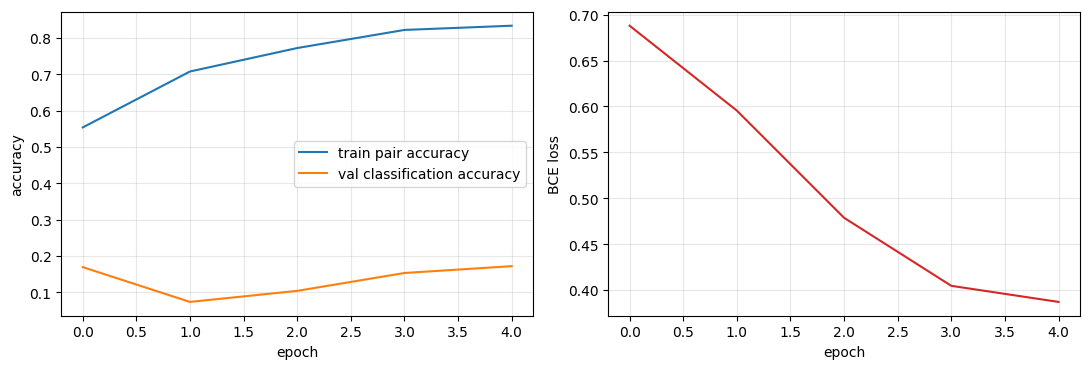

params: 15.74 M | embed time: 67.05 ms/image


In [9]:
h = result["history"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h["train_acc"], label="train pair accuracy"); ax[0].plot(h["val_acc"], label="val classification accuracy")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h["train_loss"], color="tab:red"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("BCE loss"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()


@torch.no_grad()
def benchmark(model, S, n=50):
    model.eval()
    x = torch.rand(1, 3, S, S, device=device)
    for _ in range(5):
        model.embed(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t = time.time()
    for _ in range(n):
        model.embed(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.time() - t) / n * 1000


print(f"params: {count_params(result['model']):.2f} M | embed time: {benchmark(result['model'], CFG['img_size']):.2f} ms/image")

## 9. Optional: similarity of two test images (like Table 5)

same class     : 0.7473
different class: 0.6414


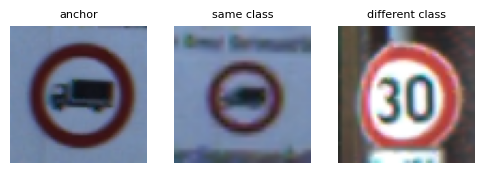

In [10]:
@torch.no_grad()
def similarity(model, xa, xb):
    ea, eb = embed_all(model, torch.stack([xa, xb]))
    return torch.sigmoid(model.pair_logits(ea[None], eb[None])).item()


yte = data["yte"]
i = 0
same = int((yte == yte[i]).nonzero()[1]) if (yte == yte[i]).sum() > 1 else i
diff = int((yte != yte[i]).nonzero()[0])
print("same class     :", round(similarity(result["model"], data["Xte"][i], data["Xte"][same]), 4))
print("different class:", round(similarity(result["model"], data["Xte"][i], data["Xte"][diff]), 4))
fig, ax = plt.subplots(1, 3, figsize=(6, 2))
for a_, k_, t_ in zip(ax, [i, same, diff], ["anchor", "same class", "different class"]):
    a_.imshow(data["Xte"][k_].permute(1, 2, 0).numpy()); a_.set_title(t_, fontsize=8); a_.axis("off")
plt.show()

## 10. Optional: all four backbones (Table 6) and ablation (Table 8)
These loops retrain several models, so they take a long time. Reduce `epochs` first.

In [11]:
RUN_BACKBONES = False
if RUN_BACKBONES:
    import pandas as pd
    rows = []
    for bb in ["mobilenet_v2", "vgg16", "resnet50", "alexnet"]:
        r = run_experiment({**CFG, "backbone": bb}, data)
        rows.append(dict(backbone=bb, test_acc=round(r["test_acc"] * 100, 2), macro_f1=round(r["macro_f1"] * 100, 2)))
    print(pd.DataFrame(rows))

In [12]:
RUN_ABLATION = False
if RUN_ABLATION:
    import pandas as pd
    rows = []
    variants = {"Full model": {}, "Without DS Block": dict(use_ds=False),
                "Without HN-FR": dict(use_hnfr=False), "Without improved Mamba": dict(use_mamba=False)}
    for name, kw in variants.items():
        r = run_experiment({**CFG, **kw}, data)
        rows.append(dict(config=name, test_acc=round(r["test_acc"] * 100, 2),
                         params_M=round(count_params(r["model"]), 2),
                         ms_per_image=round(benchmark(r["model"], CFG["img_size"]), 2)))
    print(pd.DataFrame(rows))

## 11. Website: sign recognition + damaged-sign reporting
Turns the trained SM&CNN into a web app: recognise a sign, get an automatic condition check (similarity to the reference sign + blur/lighting checks), submit a damage report with location, and review reports in an admin tab (SQLite + CSV export). The damage-reporting workflow is an application built around the paper, which itself covers recognition only.
1. **Export** the trained model + class prototypes into `bundle.pt`
2. **Write** the web app files (`%%writefile` cells)
3. **Launch** the server and a free Cloudflare tunnel -> you get a `https://....trycloudflare.com` URL
4. Optional: download everything as a zip to run the site on your own machine

In [13]:
def export_bundle(result, data, cfg, path):
    model = result["model"].eval()
    protos = build_prototypes(model, data["Xtr"], data["ytr"], data["num_classes"], cfg["support_per_class"])
    bundle = dict(cfg=dict(cfg), state={k: v.detach().cpu() for k, v in model.state_dict().items()},
                  protos=protos.cpu(), class_names=data.get("class_names"), test_acc=result["test_acc"])
    os.makedirs(os.path.dirname(path), exist_ok=True)
    torch.save(bundle, path)
    print("saved", path, f"({os.path.getsize(path) / 1e6:.1f} MB)")

WEB_DIR = "/content/sm_cnn_web"
os.makedirs(WEB_DIR, exist_ok=True)
export_bundle(result, data, CFG, f"{WEB_DIR}/bundle.pt")

saved /content/sm_cnn_web/bundle.pt (63.1 MB)


In [14]:
%%writefile /content/sm_cnn_web/model_def.py
"""Model definition (auto-extracted from the training notebook)."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def channel_shuffle_nhwc(x, groups=2):
    B, H, W, C = x.shape
    return x.view(B, H, W, groups, C // groups).transpose(3, 4).reshape(B, H, W, C)


def selective_scan_torch(u, dt, A, Bs, Cs, Ds):
    """u,dt:(B,K,D,L)  A:(K,D,N)  Bs,Cs:(B,K,N,L)  Ds:(K,D)  ->  y:(B,K,D,L)"""
    Bsz, K, D, L = u.shape
    N = A.shape[-1]
    dA = torch.exp(torch.einsum("bkdl,kdn->lbkdn", dt, A))
    dBu = torch.einsum("bkdl,bknl->lbkdn", dt * u, Bs)
    Cl = Cs.permute(3, 0, 1, 2)  # L,B,K,N
    h = u.new_zeros(Bsz, K, D, N)
    ys = []
    for l in range(L):
        h = dA[l] * h + dBu[l]
        ys.append((h * Cl[l].unsqueeze(2)).sum(-1))
    y = torch.stack(ys, dim=-1)
    return y + u * Ds[None, :, :, None]


class SS2D(nn.Module):
    """SSM branch of Fig. 2: Linear -> DWConv -> SiLU -> 2D selective scan (4 directions) -> LN -> gate."""
    def __init__(self, d_model, d_state=8, d_conv=3, expand=1, use_kernel=False):
        super().__init__()
        self.d_inner = d_inner = int(expand * d_model)
        self.d_state, self.K, self.use_kernel = d_state, 4, use_kernel
        self.dt_rank = dt_rank = max(1, math.ceil(d_model / 16))
        K = self.K
        self.in_proj = nn.Linear(d_model, d_inner * 2, bias=False)
        self.dwconv = nn.Conv2d(d_inner, d_inner, d_conv, padding=d_conv // 2, groups=d_inner)
        self.x_proj_weight = nn.Parameter(torch.randn(K, dt_rank + 2 * d_state, d_inner) * d_inner ** -0.5)
        std = dt_rank ** -0.5
        self.dt_projs_weight = nn.Parameter(torch.empty(K, d_inner, dt_rank).uniform_(-std, std))
        dt = torch.exp(torch.rand(K, d_inner) * (math.log(0.1) - math.log(1e-3)) + math.log(1e-3)).clamp(min=1e-4)
        self.dt_projs_bias = nn.Parameter(dt + torch.log(-torch.expm1(-dt)))
        self.A_logs = nn.Parameter(torch.log(torch.arange(1, d_state + 1).float().repeat(K, d_inner, 1)))
        self.Ds = nn.Parameter(torch.ones(K, d_inner))
        self.out_norm = nn.LayerNorm(d_inner)
        self.out_proj = nn.Linear(d_inner, d_model, bias=False)

    def _scan(self, xs, dts, A, Bs, Cs):
        if self.use_kernel:
            try:
                from mamba_ssm.ops.selective_scan_interface import selective_scan_fn
                B, K, D, L = xs.shape
                y = selective_scan_fn(xs.reshape(B, K * D, L), dts.reshape(B, K * D, L), A.reshape(K * D, -1),
                                      Bs.contiguous(), Cs.contiguous(), self.Ds.reshape(-1).float(),
                                      delta_bias=None, delta_softplus=False)
                return y.view(B, K, D, L)
            except Exception as e:
                print("mamba_ssm kernel unavailable -> pure PyTorch scan:", repr(e))
                self.use_kernel = False
        return selective_scan_torch(xs, dts, A, Bs, Cs, self.Ds.float())

    def scan_2d(self, x):  # x: (B,D,H,W)
        B, D, H, W = x.shape
        L = H * W
        xs = torch.stack([x.reshape(B, D, L), x.transpose(2, 3).contiguous().reshape(B, D, L)], 1)
        xs = torch.cat([xs, xs.flip(-1)], 1)  # (B,4,D,L)
        with torch.autocast(device_type=x.device.type, enabled=False):
            xs = xs.float()
            x_dbl = torch.einsum("bkdl,kcd->bkcl", xs, self.x_proj_weight.float())
            dts, Bs, Cs = torch.split(x_dbl, [self.dt_rank, self.d_state, self.d_state], dim=2)
            dts = torch.einsum("bkrl,kdr->bkdl", dts, self.dt_projs_weight.float())
            dts = F.softplus(dts + self.dt_projs_bias.float()[None, :, :, None])
            A = -torch.exp(self.A_logs.float())
            y = self._scan(xs, dts, A, Bs, Cs)
        y = y[:, :2] + y[:, 2:].flip(-1)                                   # undo the flipped scans
        y = y[:, 0] + y[:, 1].reshape(B, D, W, H).transpose(2, 3).reshape(B, D, L)  # undo the transposed scan
        return y.transpose(1, 2).reshape(B, H, W, D)

    def forward(self, x):  # (B,H,W,C)
        x, z = self.in_proj(x).chunk(2, dim=-1)
        x = F.silu(self.dwconv(x.permute(0, 3, 1, 2).contiguous()))
        y = self.out_norm(self.scan_2d(x)) * F.silu(z)
        return self.out_proj(y)


class DSBlock(nn.Module):
    """Depth-separable conv block (Fig. 3 / Eq. 2): 1x1 -> BN -> ReLU6 -> DW3x3 -> BN -> ReLU6 -> 1x1 -> BN."""
    def __init__(self, ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(ch, ch, 1, bias=False), nn.BatchNorm2d(ch), nn.ReLU6(inplace=True),
            nn.Conv2d(ch, ch, 3, padding=1, groups=ch, bias=False), nn.BatchNorm2d(ch), nn.ReLU6(inplace=True),
            nn.Conv2d(ch, ch, 1, bias=False), nn.BatchNorm2d(ch))

    def forward(self, x):
        return self.net(x)


class ConvBranch(nn.Module):
    """Original Med-Mamba style conv branch (used only for the 'without DS Block' ablation)."""
    def __init__(self, ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, ch, 1))

    def forward(self, x):
        return self.net(x)


class SSConvSSM(nn.Module):
    """Split channels -> [conv branch | SSM branch] -> concat -> channel shuffle -> residual."""
    def __init__(self, dim, d_state, use_ds, use_kernel):
        super().__init__()
        half = dim // 2
        self.ln = nn.LayerNorm(dim)
        self.ssm_norm = nn.LayerNorm(half)
        self.ssm = SS2D(half, d_state, use_kernel=use_kernel)
        self.conv = DSBlock(half) if use_ds else ConvBranch(half)

    def forward(self, x):  # (B,H,W,C)
        shortcut = x
        x1, x2 = self.ln(x).chunk(2, dim=-1)
        x1 = self.conv(x1.permute(0, 3, 1, 2).contiguous()).permute(0, 2, 3, 1)
        x2 = self.ssm(self.ssm_norm(x2))
        return shortcut + channel_shuffle_nhwc(torch.cat([x1, x2], dim=-1))


class PatchMerging(nn.Module):
    def __init__(self, dim_in, dim_out):
        super().__init__()
        self.norm = nn.LayerNorm(4 * dim_in)
        self.reduction = nn.Linear(4 * dim_in, dim_out, bias=False)

    def forward(self, x):  # (B,H,W,C) -> (B,H/2,W/2,dim_out)
        x = torch.cat([x[:, 0::2, 0::2], x[:, 1::2, 0::2], x[:, 0::2, 1::2], x[:, 1::2, 1::2]], dim=-1)
        return self.reduction(self.norm(x))


class ImprovedMamba(nn.Module):
    def __init__(self, dims=(64, 128, 256), depths=(2, 2, 2), d_state=8, use_ds=True, use_kernel=False, patch=4):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, dims[0], patch, patch)
        self.pe_norm = nn.LayerNorm(dims[0])
        self.stages, self.merges = nn.ModuleList(), nn.ModuleList()
        for i, (d, n) in enumerate(zip(dims, depths)):
            self.stages.append(nn.Sequential(*[SSConvSSM(d, d_state, use_ds, use_kernel) for _ in range(n)]))
            self.merges.append(PatchMerging(d, dims[i + 1]) if i < len(dims) - 1 else nn.Identity())
        self.norm = nn.LayerNorm(dims[-1])
        self.out_dim = dims[-1]

    def forward(self, x):
        x = self.pe_norm(self.patch_embed(x).permute(0, 2, 3, 1))
        for stage, merge in zip(self.stages, self.merges):
            x = merge(stage(x))
        return self.norm(x).mean(dim=(1, 2))  # (B, C)


def build_cnn(name, pretrained=True):
    import torchvision.models as tvm
    def mk(fn, w):
        try:
            return fn(weights=w if pretrained else None)
        except Exception as e:
            print("could not load pretrained weights -> random init:", repr(e))
            return fn(weights=None)
    if name == "vgg16":
        feat, out = mk(tvm.vgg16, tvm.VGG16_Weights.DEFAULT).features, 512
    elif name == "resnet50":
        m = mk(tvm.resnet50, tvm.ResNet50_Weights.DEFAULT)
        feat, out = nn.Sequential(*list(m.children())[:-2]), 2048
    elif name == "mobilenet_v2":
        feat, out = mk(tvm.mobilenet_v2, tvm.MobileNet_V2_Weights.DEFAULT).features, 1280
    elif name == "alexnet":
        feat, out = mk(tvm.alexnet, tvm.AlexNet_Weights.DEFAULT).features, 256
    else:
        raise ValueError(name)
    return nn.Sequential(feat, nn.AdaptiveAvgPool2d(1), nn.Flatten()), out


class HNFR(nn.Module):
    """Heterogeneous Network Feature Reconstruction (Fig. 4, Eqs. 8-14)."""
    def __init__(self, D):
        super().__init__()
        self.att = nn.Linear(2 * D, 1, bias=False)   # learnable attention parameter a
        self.fc1 = nn.Linear(2 * D, D)
        self.fc2 = nn.Linear(3 * D, D)

    def forward(self, y1, y2):
        Y = torch.cat([y1, y2], dim=-1)                  # Eq. 8
        theta = torch.sigmoid(self.att(Y))               # Eq. 9
        psi = y1 * theta                                 # Eq. 10
        z1 = F.relu(self.fc1(torch.cat([psi, y2], -1)))  # Eq. 11, 13
        return F.relu(self.fc2(torch.cat([z1, Y], -1)))  # Eq. 12, 14


class SiameseSMCNN(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D = cfg["embed_dim"]
        self.cnn, cnn_dim = build_cnn(cfg["backbone"], cfg["pretrained"])
        self.proj1 = nn.Linear(cnn_dim, D)
        self.mamba = None
        if cfg["use_mamba"]:
            self.mamba = ImprovedMamba(cfg["mamba_dims"], cfg["mamba_depths"], cfg["d_state"],
                                       cfg["use_ds"], cfg["use_mamba_ssm_kernel"])
            self.proj2 = nn.Linear(self.mamba.out_dim, D)
            self.fuse = HNFR(D) if cfg["use_hnfr"] else nn.Sequential(nn.Linear(2 * D, D), nn.ReLU())
        self.head = nn.Sequential(nn.Linear(D, D // 2), nn.ReLU(), nn.Linear(D // 2, 1))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def embed(self, x):  # x: float in [0,1], (B,3,S,S)
        x = (x - self.mean) / self.std
        y1 = self.proj1(self.cnn(x))
        if self.mamba is None:
            return F.relu(y1)
        y2 = self.proj2(self.mamba(x))
        return self.fuse(y1, y2)

    def pair_logits(self, e1, e2):
        return self.head((e1 - e2).abs()).squeeze(-1)  # similarity logit (>0 => same class)

    def set_cnn_trainable(self, flag):
        for p in self.cnn.parameters():
            p.requires_grad = flag


def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6


Writing /content/sm_cnn_web/model_def.py


In [15]:
%%writefile /content/sm_cnn_web/server.py
"""Web server for the SM&CNN traffic-sign recogniser.
Usage:  python server.py --bundle bundle.pt [--port 5000] [--host 0.0.0.0]
"""
import argparse, csv, datetime, io, os, secrets, sqlite3, traceback, uuid
import numpy as np
import torch
from flask import Flask, abort, jsonify, request, Response, send_from_directory
from PIL import Image
from model_def import SiameseSMCNN

GTSRB_NAMES = ["Speed limit 20", "Speed limit 30", "Speed limit 50", "Speed limit 60", "Speed limit 70",
    "Speed limit 80", "End of speed limit 80", "Speed limit 100", "Speed limit 120", "No passing",
    "No passing for vehicles over 3.5 t", "Right-of-way at next intersection", "Priority road", "Yield", "Stop",
    "No vehicles", "Vehicles over 3.5 t prohibited", "No entry", "General caution", "Dangerous curve left",
    "Dangerous curve right", "Double curve", "Bumpy road", "Slippery road", "Road narrows on the right",
    "Road work", "Traffic signals", "Pedestrians", "Children crossing", "Bicycles crossing", "Beware of ice/snow",
    "Wild animals crossing", "End of all speed and passing limits", "Turn right ahead", "Turn left ahead",
    "Ahead only", "Go straight or right", "Go straight or left", "Keep right", "Keep left",
    "Roundabout mandatory", "End of no passing", "End of no passing for vehicles over 3.5 t"]

HERE = os.path.dirname(os.path.abspath(__file__))
DATA_DIR = os.environ.get("DATA_DIR", os.path.join(HERE, "data"))
UPLOADS = os.path.join(DATA_DIR, "uploads")
DB = os.path.join(DATA_DIR, "reports.db")
os.makedirs(UPLOADS, exist_ok=True)
ADMIN_TOKEN = os.environ.get("ADMIN_TOKEN") or secrets.token_urlsafe(8)
SIM_THRESHOLD = float(os.environ.get("SIM_THRESHOLD", "0.6"))  # below this similarity to the reference sign => suspicious
ISSUES = ["Faded / discoloured", "Bent or tilted", "Broken / cracked", "Vandalised (graffiti, stickers)",
          "Blocked by vegetation or object", "Missing sign / only pole", "Hard to read (other)"]
STATUSES = ["open", "in review", "resolved"]
app = Flask(__name__, static_folder=None)
app.config["MAX_CONTENT_LENGTH"] = 10 * 1024 * 1024
S = {}  # model state


def db():
    con = sqlite3.connect(DB)
    con.row_factory = sqlite3.Row
    return con


def init_db():
    with db() as c:
        c.execute("""CREATE TABLE IF NOT EXISTS reports(
            id INTEGER PRIMARY KEY AUTOINCREMENT, created TEXT, status TEXT DEFAULT 'open',
            sign_class INTEGER, sign_label TEXT, similarity REAL, confidence REAL, level TEXT, auto_flags TEXT,
            issue_type TEXT, notes TEXT, lat REAL, lon REAL, address TEXT, reporter TEXT, contact TEXT, image TEXT)""")


def load_bundle(path):
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    b = torch.load(path, map_location="cpu", weights_only=False)
    cfg = dict(b["cfg"]); cfg["pretrained"] = False
    model = SiameseSMCNN(cfg)
    model.load_state_dict(b["state"])
    S.update(model=model.to(dev).eval(), dev=dev, cfg=cfg, protos=b["protos"].to(dev),
             test_acc=b.get("test_acc"), size=cfg["img_size"])
    names = b.get("class_names") or [str(i) for i in range(S["protos"].shape[0])]
    if cfg["dataset"] == "GTSRB" and len(names) == 43:
        names = [f"{i}: {n}" for i, n in enumerate(GTSRB_NAMES)]
    S["names"] = [str(n) for n in names]


def read_pil(field):
    f = request.files.get(field)
    if f is None:
        raise ValueError(f"missing image field '{field}'")
    try:
        return Image.open(f.stream).convert("RGB")
    except Exception:
        raise ValueError("could not read the uploaded file as an image")


def to_tensor(img):
    img = img.resize((S["size"], S["size"]), Image.BILINEAR)
    return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).float().div(255).unsqueeze(0).to(S["dev"])


@torch.no_grad()
def embed(x):
    with torch.autocast(device_type=S["dev"].type, dtype=torch.float16, enabled=S["dev"].type == "cuda"):
        return S["model"].embed(x).float()


def quality(img):
    """Simple photo-quality indicators (heuristics): sharpness (variance of Laplacian), brightness, contrast."""
    g = np.asarray(img.convert("L").resize((128, 128), Image.BILINEAR), dtype=np.float32)
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    q = dict(sharpness=round(float(lap.var()), 1), brightness=round(float(g.mean()), 1), contrast=round(float(g.std()), 1))
    flags = []
    if q["sharpness"] < 40: flags.append("blurry photo")
    if q["brightness"] < 50: flags.append("too dark")
    elif q["brightness"] > 215: flags.append("overexposed")
    if q["contrast"] < 25: flags.append("low contrast / faded")
    return q, flags


@torch.no_grad()
def analyze(img):
    """SM&CNN recognition + similarity to the reference (prototype) of the recognised class + photo quality."""
    e = embed(to_tensor(img))
    logits = S["model"].head((e - S["protos"]).abs()).squeeze(-1)
    sim, share = torch.sigmoid(logits), torch.softmax(logits, 0)
    top = torch.topk(logits, min(5, len(S["names"]))).indices.tolist()
    results = [dict(label=S["names"][i], class_id=i, similarity=round(sim[i].item(), 4),
                    confidence=round(share[i].item(), 4)) for i in top]
    q, flags = quality(img)
    if results[0]["similarity"] < SIM_THRESHOLD:
        flags.append("low match to the reference sign (possible damage/obstruction)")
    level = "ok" if not flags else ("review" if len(flags) == 1 else "attention")
    return dict(results=results, quality=q, flags=flags, level=level)


def need_admin():
    t = request.headers.get("X-Admin-Token") or request.args.get("token") or ""
    if not secrets.compare_digest(t.encode(), ADMIN_TOKEN.encode()):
        abort(401, "admin token required")


@app.after_request
def cors(r):  # lets index.html opened from another origin call this API
    r.headers["Access-Control-Allow-Origin"] = "*"
    r.headers["Access-Control-Allow-Headers"] = "*"
    r.headers["Access-Control-Allow-Methods"] = "GET,POST,PATCH,OPTIONS"
    return r


@app.errorhandler(Exception)
def fail(e):
    from werkzeug.exceptions import HTTPException
    if isinstance(e, ValueError):
        return jsonify(error=str(e)), 400
    if isinstance(e, HTTPException):
        return jsonify(error=e.description), e.code
    traceback.print_exc()
    return jsonify(error=f"server error: {type(e).__name__}: {e}"), 500


@app.route("/")
def index():
    return Response(open(os.path.join(HERE, "index.html"), encoding="utf-8").read(), mimetype="text/html")


@app.route("/api/info")
def info():
    c = S["cfg"]
    return jsonify(dataset=c["dataset"], backbone=c["backbone"], classes=len(S["names"]), image_size=S["size"],
                   test_accuracy=S["test_acc"], device=str(S["dev"]), mamba=c["use_mamba"], hnfr=c["use_hnfr"],
                   issues=ISSUES, statuses=STATUSES, sim_threshold=SIM_THRESHOLD)


@app.route("/api/predict", methods=["POST"])
def predict():
    return jsonify(analyze(read_pil("image")))


@app.route("/api/compare", methods=["POST"])
@torch.no_grad()
def compare():
    ea, eb = embed(to_tensor(read_pil("a"))), embed(to_tensor(read_pil("b")))
    s = torch.sigmoid(S["model"].pair_logits(ea, eb)).item()
    return jsonify(similarity=round(s, 4), same_class=s > 0.5)


def num(v, lo, hi, name):
    if v in (None, ""):
        return None
    try:
        x = float(v)
    except ValueError:
        raise ValueError(f"{name} must be a number")
    if not lo <= x <= hi:
        raise ValueError(f"{name} out of range")
    return x


@app.route("/api/report", methods=["POST"])
def report():
    img = read_pil("image")
    f = request.form
    issue = f.get("issue_type", "")
    if issue not in ISSUES:
        raise ValueError("please choose the type of problem")
    lat, lon = num(f.get("lat"), -90, 90, "latitude"), num(f.get("lon"), -180, 180, "longitude")
    address = f.get("address", "").strip()[:200]
    if (lat is None or lon is None) and not address:
        raise ValueError("please give the location (GPS coordinates or an address)")
    a = analyze(img)
    top = a["results"][0]
    fname = uuid.uuid4().hex + ".jpg"
    img.thumbnail((1600, 1600))
    img.save(os.path.join(UPLOADS, fname), quality=90)
    with db() as c:
        cur = c.execute("""INSERT INTO reports(created,sign_class,sign_label,similarity,confidence,level,auto_flags,issue_type,
            notes,lat,lon,address,reporter,contact,image) VALUES(?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)""",
            (datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z", top["class_id"], top["label"], top["similarity"],
             top["confidence"], a["level"], "; ".join(a["flags"]), issue, f.get("notes", "").strip()[:1000], lat, lon,
             address, f.get("reporter", "").strip()[:100], f.get("contact", "").strip()[:100], fname))
    return jsonify(id=cur.lastrowid, analysis=a)


@app.route("/uploads/<path:name>")
def uploads(name):
    return send_from_directory(UPLOADS, name)


@app.route("/api/reports")
def reports():
    need_admin()
    st = request.args.get("status")
    with db() as c:
        rows = c.execute("SELECT * FROM reports" + (" WHERE status=?" if st in STATUSES else "") + " ORDER BY id DESC",
                         (st,) if st in STATUSES else ()).fetchall()
    return jsonify(reports=[dict(r) for r in rows])


@app.route("/api/reports/<int:rid>", methods=["PATCH"])
def update_report(rid):
    need_admin()
    status = (request.get_json(silent=True) or {}).get("status")
    if status not in STATUSES:
        raise ValueError("invalid status")
    with db() as c:
        c.execute("UPDATE reports SET status=? WHERE id=?", (status, rid))
    return jsonify(ok=True)


@app.route("/api/reports.csv")
def reports_csv():
    need_admin()
    with db() as c:
        rows = c.execute("SELECT * FROM reports ORDER BY id").fetchall()
    out = io.StringIO()
    w = csv.writer(out)
    w.writerow(rows[0].keys() if rows else ["id"])
    w.writerows([list(r) for r in rows])
    return Response(out.getvalue(), mimetype="text/csv", headers={"Content-Disposition": "attachment; filename=reports.csv"})


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--bundle", required=True)
    ap.add_argument("--host", default="0.0.0.0")
    ap.add_argument("--port", type=int, default=5000)
    a = ap.parse_args()
    load_bundle(a.bundle)
    init_db()
    print(f"model loaded on {S['dev']} | {len(S['names'])} classes | serving on {a.host}:{a.port}")
    print(f"ADMIN TOKEN (needed for the Reports tab): {ADMIN_TOKEN}")
    app.run(host=a.host, port=a.port, threaded=True)


Writing /content/sm_cnn_web/server.py


In [16]:
%%writefile /content/sm_cnn_web/index.html
<!doctype html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Traffic Sign Recognition &amp; Damage Reporting</title>
<style>
:root{--bg:#f6f7f9;--card:#fff;--tx:#14171a;--mu:#667;--ac:#d9480f;--bd:#e1e4e8;--bar:#fde3d3;--ok:#2b8a3e;--rv:#e67700;--at:#c92a2a}
@media (prefers-color-scheme:dark){:root{--bg:#111316;--card:#1b1e22;--tx:#eceef0;--mu:#9aa1a9;--ac:#ff8a4c;--bd:#2c3036;--bar:#3a2a20;--ok:#69db7c;--rv:#ffa94d;--at:#ff6b6b}}
*{box-sizing:border-box}body{margin:0;font:16px/1.5 system-ui,sans-serif;background:var(--bg);color:var(--tx)}
main{max-width:920px;margin:0 auto;padding:24px 16px 48px}h1{font-size:1.6rem;margin:.2em 0}p.sub{color:var(--mu);margin:0 0 18px}
.card{background:var(--card);border:1px solid var(--bd);border-radius:14px;padding:18px;margin-bottom:16px}
.tabs{display:flex;gap:8px;margin-bottom:14px;flex-wrap:wrap}.tabs button{flex:1;min-width:130px;padding:10px;border:1px solid var(--bd);background:var(--card);color:var(--tx);border-radius:10px;cursor:pointer;font:inherit}
.tabs button.on{background:var(--ac);border-color:var(--ac);color:#fff}
.drop{border:2px dashed var(--bd);border-radius:12px;padding:20px;text-align:center;color:var(--mu);cursor:pointer;min-height:140px;display:flex;align-items:center;justify-content:center;flex-direction:column;gap:6px}
.drop.over{border-color:var(--ac)}.drop img{max-height:140px;max-width:100%;border-radius:8px}
.row{display:grid;grid-template-columns:1fr 1fr;gap:12px}@media(max-width:600px){.row{grid-template-columns:1fr}}
label.f{display:block;font-size:.9rem;color:var(--mu);margin-top:10px}input,select,textarea{width:100%;padding:9px;border:1px solid var(--bd);border-radius:8px;background:var(--bg);color:var(--tx);font:inherit}
button.go{margin-top:14px;padding:11px 22px;border:0;border-radius:10px;background:var(--ac);color:#fff;font:inherit;cursor:pointer}button.go:disabled{opacity:.5}
button.sm{padding:6px 10px;border:1px solid var(--bd);border-radius:8px;background:var(--card);color:var(--tx);cursor:pointer;font:inherit;margin-top:6px}
.res{margin-top:14px}.r{position:relative;border-radius:8px;overflow:hidden;margin-bottom:8px;border:1px solid var(--bd)}.r i{position:absolute;inset:0 auto 0 0;background:var(--bar)}
.r span{position:relative;display:flex;justify-content:space-between;padding:8px 12px;gap:12px}.r.top{border-color:var(--ac)}
.badge{display:inline-block;padding:3px 10px;border-radius:99px;color:#fff;font-size:.85rem;margin:6px 0}.ok{background:var(--ok)}.review{background:var(--rv)}.attention{background:var(--at)}
.mu{color:var(--mu);font-size:.9rem}.err{color:var(--at);margin-top:10px}.big{font-size:2rem;font-weight:650}
table{width:100%;border-collapse:collapse;font-size:.88rem}th,td{border-bottom:1px solid var(--bd);padding:6px;text-align:left;vertical-align:top}td img{width:70px;border-radius:6px}.sc{overflow-x:auto}
</style></head><body><main>
<h1>Traffic Sign Recognition &amp; Damage Reporting</h1>
<p class="sub">Siamese-Mamba&amp;CNN with HN-FR feature reconstruction, used to recognise signs and flag ones that need maintenance</p>
<div class="card mu" id="info">loading model info…</div>
<div class="tabs"><button class="on" data-t="rec">Recognize</button><button data-t="rep">Report damaged sign</button><button data-t="cmp">Compare</button><button data-t="adm">Reports (admin)</button></div>

<div class="card" id="rec"><label class="drop" id="d1"><input type="file" accept="image/*" hidden id="f1"><b>Drop a traffic sign photo</b><span>or click to choose</span></label>
<button class="go" id="b1" disabled>Recognize</button><div class="res" id="o1"></div></div>

<div class="card" id="rep" hidden>
 <div class="row"><div><label class="drop" id="d4"><input type="file" accept="image/*" hidden id="f4"><b>Photo of the sign</b><span>close-up, as sharp as possible</span></label></div>
 <div id="o4" class="res" style="margin:0"><span class="mu">The model will check the photo as soon as you add it.</span></div></div>
 <label class="f">Problem type *</label><select id="issue"></select>
 <label class="f">Notes</label><textarea id="notes" rows="2" maxlength="1000" placeholder="e.g. sign bent after storm, faces the school entrance"></textarea>
 <div class="row"><div><label class="f">Latitude</label><input id="lat" inputmode="decimal"></div><div><label class="f">Longitude</label><input id="lon" inputmode="decimal"></div></div>
 <button class="sm" id="gps" type="button">📍 Use my current location</button>
 <label class="f">…or address / landmark</label><input id="addr" maxlength="200" placeholder="Street, area, nearest landmark">
 <div class="row"><div><label class="f">Your name (optional)</label><input id="rname" maxlength="100"></div><div><label class="f">Contact (optional)</label><input id="rcontact" maxlength="100"></div></div>
 <button class="go" id="b4" disabled>Submit report</button><div class="res" id="o4b"></div>
 <p class="mu">Automatic flags are indicators from the model and simple photo checks, not proof of damage. A maintenance officer reviews every report.</p></div>

<div class="card" id="cmp" hidden><div class="row"><label class="drop" id="d2"><input type="file" accept="image/*" hidden id="f2"><b>Sign A</b></label><label class="drop" id="d3"><input type="file" accept="image/*" hidden id="f3"><b>Sign B</b></label></div>
<button class="go" id="b2" disabled>Compare</button><div class="res" id="o2"></div></div>

<div class="card" id="adm" hidden><div class="row"><div><label class="f">Admin token (printed when the server starts)</label><input id="tok" type="password"></div>
<div><label class="f">Filter</label><select id="flt"><option value="">all</option></select></div></div>
<button class="go" id="b5">Load reports</button> <button class="sm" id="csv">Download CSV</button><div class="res sc" id="o5"></div></div>
</main>
<script>
const $=s=>document.querySelector(s),files={},API=(new URLSearchParams(location.search).get("api")||(location.protocol==="file:"?"http://localhost:5000":"")).replace(/\/$/,"");
const esc=t=>String(t??"").replace(/[&<>"']/g,c=>({"&":"&amp;","<":"&lt;",">":"&gt;",'"':"&quot;","'":"&#39;"}[c]));
const NET="Cannot reach the server. Open the site via the server URL (trycloudflare link or http://localhost:5000), check server.py is running, and wait ~1 min after a new tunnel link.";
async function api(url,opt={}){let r;try{r=await fetch(API+url,opt)}catch(e){throw new Error(NET)}
 let j;try{j=await r.json()}catch(_){throw new Error("server returned HTTP "+r.status)}if(!r.ok)throw new Error(j.error||r.statusText);return j}
const show=(el,p,f)=>{el.innerHTML="<span class='mu'>working…</span>";return p.then(j=>el.innerHTML=f(j)).catch(e=>el.innerHTML=`<div class="err">${esc(e.message)}</div>`)};
function wire(id,key,btn,need,cb){const d=$("#d"+id),inp=$("#f"+id);
 const set=f=>{if(!f||!f.type.startsWith("image/"))return;files[key]=f;d.innerHTML=`<img alt="preview" src="${URL.createObjectURL(f)}"><span>${esc(f.name)}</span>`;d.appendChild(inp);$(btn).disabled=!need.every(k=>files[k]);cb&&cb()};
 inp.onchange=()=>set(inp.files[0]);d.ondragover=e=>{e.preventDefault();d.classList.add("over")};d.ondragleave=()=>d.classList.remove("over");d.ondrop=e=>{e.preventDefault();d.classList.remove("over");set(e.dataTransfer.files[0])}}
const fd1=(k,f)=>{const d=new FormData();d.append(k,f);return d};
const LV={ok:"Looks fine",review:"Needs review",attention:"Likely damaged / obstructed / poor photo"};
const assess=j=>`<span class="badge ${j.level}">${LV[j.level]}</span>`+(j.flags.length?`<div class="mu">⚠ ${j.flags.map(esc).join(" · ")}</div>`:"")+
 j.results.slice(0,3).map((x,i)=>`<div class="r ${i?"":"top"}"><i style="width:${x.confidence*100}%"></i><span><b>${esc(x.label)}</b><span>${(x.confidence*100).toFixed(1)}% · sim ${x.similarity.toFixed(3)}</span></span></div>`).join("")+
 `<div class="mu">sharpness ${j.quality.sharpness} · brightness ${j.quality.brightness} · contrast ${j.quality.contrast}</div>`;
wire(1,"a","#b1",["a"]);wire(2,"p","#b2",["p","q"]);wire(3,"q","#b2",["p","q"]);
wire(4,"r","#b4",["r"],()=>show($("#o4"),api("/api/predict",{method:"POST",body:fd1("image",files.r)}),assess));
document.querySelectorAll(".tabs button").forEach(b=>b.onclick=()=>{document.querySelectorAll(".tabs button").forEach(x=>x.classList.toggle("on",x===b));
 ["rec","rep","cmp","adm"].forEach(t=>$("#"+t).hidden=b.dataset.t!==t)});
$("#b1").onclick=()=>show($("#o1"),api("/api/predict",{method:"POST",body:fd1("image",files.a)}),assess);
$("#b2").onclick=()=>{const d=new FormData();d.append("a",files.p);d.append("b",files.q);
 show($("#o2"),api("/api/compare",{method:"POST",body:d}),j=>`<div class="big">${(j.similarity*100).toFixed(1)}% similar</div>${j.same_class?"Same sign class ✅":"Different sign classes ❌"}`)};
$("#gps").onclick=()=>navigator.geolocation?navigator.geolocation.getCurrentPosition(p=>{$("#lat").value=p.coords.latitude.toFixed(6);$("#lon").value=p.coords.longitude.toFixed(6)},e=>alert("Could not get location: "+e.message)):alert("Geolocation not supported");
$("#b4").onclick=()=>{const d=new FormData();d.append("image",files.r);
 [["issue_type","issue"],["notes","notes"],["lat","lat"],["lon","lon"],["address","addr"],["reporter","rname"],["contact","rcontact"]].forEach(([k,i])=>d.append(k,$("#"+i).value));
 show($("#o4b"),api("/api/report",{method:"POST",body:d}),j=>`<span class="badge ok">Report #${j.id} submitted</span><div class="mu">Thank you. Automatic assessment: ${LV[j.analysis.level]}.</div>`)};
const hdr=()=>({"X-Admin-Token":$("#tok").value});
$("#b5").onclick=()=>show($("#o5"),api("/api/reports"+($("#flt").value?"?status="+$("#flt").value:""),{headers:hdr()}),j=>!j.reports.length?"No reports yet.":
 `<table><tr><th>#</th><th>Photo</th><th>Sign</th><th>Problem</th><th>Auto check</th><th>Where</th><th>Status</th></tr>`+j.reports.map(r=>`<tr><td>${r.id}<br><span class="mu">${esc(r.created.slice(0,10))}</span></td>
 <td><a href="${API}/uploads/${esc(r.image)}" target="_blank"><img alt="report photo" src="${API}/uploads/${esc(r.image)}"></a></td><td>${esc(r.sign_label)}<br><span class="mu">sim ${(+r.similarity).toFixed(2)}</span></td>
 <td>${esc(r.issue_type)}<br><span class="mu">${esc(r.notes)}</span></td><td><span class="badge ${esc(r.level)}">${esc(r.level)}</span><br><span class="mu">${esc(r.auto_flags)}</span></td>
 <td>${r.lat!=null?`<a target="_blank" href="https://www.google.com/maps?q=${r.lat},${r.lon}">${(+r.lat).toFixed(4)}, ${(+r.lon).toFixed(4)}</a><br>`:""}${esc(r.address)}<br><span class="mu">${esc(r.reporter)} ${esc(r.contact)}</span></td>
 <td><select onchange="setStatus(${r.id},this.value)">${ST.map(s=>`<option ${s==r.status?"selected":""}>${s}</option>`).join("")}</select></td></tr>`).join("")+"</table>");
let ST=["open","in review","resolved"];
window.setStatus=(id,s)=>api("/api/reports/"+id,{method:"PATCH",headers:{...hdr(),"Content-Type":"application/json"},body:JSON.stringify({status:s})}).catch(e=>alert(e.message));
$("#csv").onclick=()=>{if(!$("#tok").value)return alert("Enter the admin token");open(API+"/api/reports.csv?token="+encodeURIComponent($("#tok").value))};
api("/api/info").then(i=>{ST=i.statuses;$("#issue").innerHTML=i.issues.map(x=>`<option>${esc(x)}</option>`).join("");$("#flt").innerHTML+=ST.map(s=>`<option>${s}</option>`).join("");
 $("#info").innerHTML=`Model: <b>${esc(i.backbone)}</b> + ${i.mamba?"improved Mamba":"(no Mamba)"}${i.hnfr?" + HN-FR":""} · trained on <b>${esc(i.dataset)}</b> (${i.classes} classes) · ${i.image_size}px · ${esc(i.device)}`+(i.test_accuracy!=null?` · test accuracy <b>${(i.test_accuracy*100).toFixed(2)}%</b>`:"")}).catch(e=>$("#info").textContent=e.message);
</script></body></html>


Writing /content/sm_cnn_web/index.html


In [17]:
%%writefile /content/sm_cnn_web/requirements.txt
torch
torchvision
flask
pillow
numpy


Writing /content/sm_cnn_web/requirements.txt


In [18]:
%%writefile /content/sm_cnn_web/README.md
# Traffic sign recognition + damaged-sign reporting (SM&CNN)

Recognition uses the Siamese-Mamba&CNN model from "Improved road traffic sign recognition from feature reconstruction"
(Sci. Rep. 15:42656). The **damage-reporting workflow is an application built around that model** (the paper itself does not
detect damage).

How the automatic check works (indicators, not proof):
* similarity of the photo to the reference prototype of the recognised sign class (low = faded/damaged/obstructed),
* simple photo-quality checks: blur, darkness/overexposure, low contrast.
Thresholds: env `SIM_THRESHOLD` (default 0.6). A human reviews every report in the admin tab.

Run: `pip install -r requirements.txt` then `ADMIN_TOKEN=yourtoken python server.py --bundle bundle.pt` -> http://localhost:5000
Reports + photos are stored in `./data` (SQLite `reports.db`, `uploads/`); set `DATA_DIR` to change.
API: /api/predict, /api/compare, POST /api/report, admin (token): GET /api/reports, PATCH /api/reports/<id>, GET /api/reports.csv


Writing /content/sm_cnn_web/README.md


In [19]:
import subprocess, re, time, os
os.system("pip install -q flask")
if not os.path.exists("/usr/local/bin/cloudflared"):
    os.system("wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /usr/local/bin/cloudflared && chmod +x /usr/local/bin/cloudflared")

os.system("pkill -f server.py; pkill -f cloudflared")
import secrets
ADMIN_TOKEN = secrets.token_urlsafe(8)
server = subprocess.Popen(["python", "server.py", "--bundle", "bundle.pt", "--port", "5000"], cwd=WEB_DIR, env={**os.environ, "ADMIN_TOKEN": ADMIN_TOKEN, "DATA_DIR": "/content/sm_cnn_web/data"},
                          stdout=open("/content/server.log", "w"), stderr=subprocess.STDOUT)
time.sleep(8)
print(open("/content/server.log").read())
tunnel = subprocess.Popen(["cloudflared", "tunnel", "--url", "http://localhost:5000"],
                          stderr=subprocess.PIPE, text=True)
url, t0 = None, time.time()
while url is None and time.time() - t0 < 90:
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", tunnel.stderr.readline())
    url = m.group(0) if m else None
print("\n>>> ADMIN TOKEN (Reports tab):", ADMIN_TOKEN)
print(">>> Your website:", url or "tunnel failed - check /content/server.log, or use the local instructions in README.md")
# keep this notebook session running while you use the site (stop the cell to shut it down)

model loaded on cuda | 43 classes | serving on 0.0.0.0:5000
ADMIN TOKEN (needed for the Reports tab): z5gx1081S7E
 * Serving Flask app 'server'
 * Debug mode: off
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
Press CTRL+C to quit


>>> ADMIN TOKEN (Reports tab): z5gx1081S7E
>>> Your website: https://lesser-photography-estimation-plug.trycloudflare.com


In [20]:
# Optional: download the whole website (with bundle.pt) to run locally
import shutil
from google.colab import files
shutil.make_archive("/content/sm_cnn_web", "zip", WEB_DIR)
files.download("/content/sm_cnn_web.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>